## Подключение библиотек и загрузка данных

In [78]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [79]:
df = pd.read_csv('ИСИТ_1_практика_Ответы_на_форму_1.csv')
df.head()

,Отметка времени,"Как вы себя чувствуете, когда оказались в центре внимания в малознакомой компании?",Как чаще всего принимаются ваши повседневные решения о покупках?,"Покупая сложную технику или мебель, какой подход вам ближе?",Что вы выберете при покупке повседневной вещи?,Быстро ли твой телефон разряжается?,Ты часто снимаешь на телефон фото/видео?,"При выборе предмета интерьера или одежды, что станет решающим фактором?",Часто ли твой телефон тормозит/лагает?,"Тебе важно, чтобы все приложения со временем работали одинаково?",Любите ли вы путешествовать?,Как часто ты меняешь смартфон на новый?,Как часто вы играете в видеоигры?,Часто ли вы публикуете фотографии или видео в социальных сетях?,Часто ли вы смотрите фильмы и сериалы на телефоне?,Цвет глаз?,Ближайшая станция метро?,У тебя айфон или андроид?
0,11.09.2026 20:01:26,Комфортно,Рационально,Чтобы всё сразу работало из коробки,Какой-то уникальный вариант,Да,Нет,"Дизайн, эстетика",Нет,Да,Да,4,5,Нет,Да,Зеленый,Юго-западная,Айфон
1,11.09.2026 20:01:27,Комфортно,Рационально,Чтобы всё сразу работало из коробки,Какой-то уникальный вариант,Да,Да,"Долговечность, польза",Нет,Да,Да,3,1,Да,Да,Карий,Бульвар Дмитрия Донского,Айфон
2,11.09.2026 20:01:38,Комфортно,Рационально,Чтобы всё сразу работало из коробки,Что-то популярное,Нет,Да,"Дизайн, эстетика",Нет,Да,Да,3,1,Нет,Нет,Карий,Братиславская,Айфон
3,11.09.2026 20:01:41,Дискомфортно,Рационально,Чтобы всё сразу работало из коробки,Какой-то уникальный вариант,Да,Нет,"Долговечность, польза",Нет,Да,Да,3,0,Нет,Нет,Серый,Авиамоторная,Айфон
4,11.09.2026 20:02:11,Комфортно,Рационально,Чтобы всё сразу работало из коробки,Что-то популярное,Да,Нет,"Долговечность, польза",Да,Да,Да,4,6,Нет,Нет,Зеленый,Волжская,Андроид


## Предобработка данных

In [80]:
df = df.drop(columns=['Отметка времени', 'Цвет глаз?', 'Ближайшая станция метро?'])
df = df.dropna()

# удаляем выброс
df = df[df["Как часто вы играете в видеоигры?"] < 100]

# целевая переменная - выбор айфона или андроида
y = df['У тебя айфон или андроид?'].map({'Айфон': 0, 'Андроид': 1}) # потому что андроид лучше )
X = df.drop(columns=['У тебя айфон или андроид?'])

X = pd.get_dummies(X, drop_first=True)
X.head()

,Как часто ты меняешь смартфон на новый?,Как часто вы играете в видеоигры?,"Как вы себя чувствуете, когда оказались в центре внимания в малознакомой компании?_Комфортно",Как чаще всего принимаются ваши повседневные решения о покупках?_Эмоционально,"Покупая сложную технику или мебель, какой подход вам ближе?_Чтобы всё сразу работало из коробки",Что вы выберете при покупке повседневной вещи?_Что-то популярное,Быстро ли твой телефон разряжается?_Нет,Ты часто снимаешь на телефон фото/видео?_Нет,"При выборе предмета интерьера или одежды, что станет решающим фактором?_Долговечность, польза",Часто ли твой телефон тормозит/лагает?_Нет,"Тебе важно, чтобы все приложения со временем работали одинаково?_Нет",Любите ли вы путешествовать?_Нет,Часто ли вы публикуете фотографии или видео в социальных сетях?_Нет,Часто ли вы смотрите фильмы и сериалы на телефоне?_Нет
0,4,5,True,False,True,False,False,True,False,True,False,False,True,False
1,3,1,True,False,True,False,False,False,True,True,False,False,False,False
2,3,1,True,False,True,True,True,False,False,True,False,False,True,True
3,3,0,False,False,True,False,False,True,True,True,False,False,True,True
4,4,6,True,False,True,True,False,True,True,False,False,False,True,True


In [81]:
print(f"Размер выборки: {len(y)} человек")

Размер выборки: 43 человек


## Разделение на обучающую и тестовую выборки

In [116]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

print(f"Обучающая выборка: {X_train.shape[0]} человек")
print(f"Тестовая выборка: {X_test.shape[0]} человек")

Обучающая выборка: 36 человек
Тестовая выборка: 7 человек


## Масштабирование признаков 

In [117]:
scaler = StandardScaler() 
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## Поиск лучшего параметра k (Метод локтя)

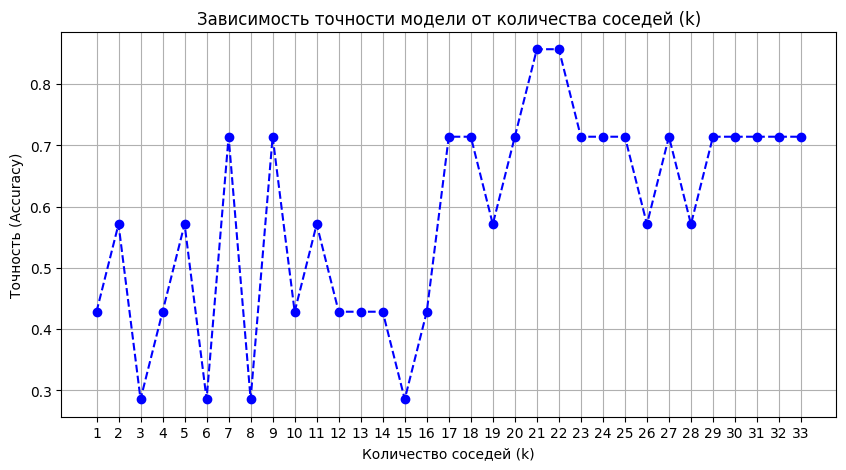

Лучшее значение k: 21
Максимальная точность: 85.71%


In [118]:
k_range = range(1, 34)
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred))

plt.figure(figsize=(10, 5))
plt.plot(k_range, accuracies, marker='o', linestyle='--', color='b')
plt.title('Зависимость точности модели от количества соседей (k)')
plt.xlabel('Количество соседей (k)')
plt.ylabel('Точность (Accuracy)')
plt.xticks(k_range)
plt.grid(True)
plt.show()

# Находим лучшее k
best_k = k_range[np.argmax(accuracies)]
best_accuracy = max(accuracies)
print(f"Лучшее значение k: {best_k}")
print(f"Максимальная точность: {best_accuracy:.2%}")

## Финальное обучение и отчет по качеству

In [124]:
# Обучаем финальную модель с лучшим k
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)
y_pred_final = best_knn.predict(X_test_scaled)
pd.DataFrame({
    'y_true': y_test,
    'y_pred': y_pred_final
})

,y_true,y_pred
38,1,1
24,1,1
25,0,0
37,1,1
34,1,1
40,0,1
4,1,1


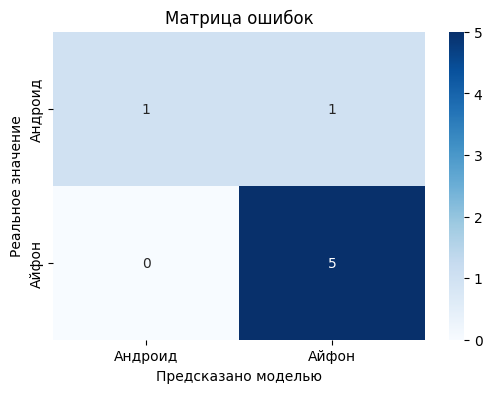

In [125]:
cm = confusion_matrix(y_test, y_pred_final)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Андроид', 'Айфон'], 
            yticklabels=['Андроид', 'Айфон'])
plt.xlabel('Предсказано моделью')
plt.ylabel('Реальное значение')
plt.title('Матрица ошибок')
plt.show()

In [126]:
info_about_us = pd.read_csv("info_about_us.csv").drop(columns=['Цвет глаз?', 'Ближайшая станция метро?'])
info_about_vlada = info_about_us[info_about_us['Имя'] == "Влада"].drop(columns=["Имя"])
info_about_alla = info_about_us[info_about_us['Имя'] == "Алла"].drop(columns=["Имя"])

data_about_us = {
    "Vlada": info_about_vlada,
    "Alla": info_about_alla
}

In [127]:
for name, df_us in data_about_us.items():
    y_us = df_us['У тебя айфон или андроид?'].map({'Айфон': 0, 'Андроид': 1})
    X_us = df_us.drop(columns=['У тебя айфон или андроид?'])

    X_us = pd.get_dummies(X_us, drop_first=True)
    X_us = X_us.reindex(columns=X_train.columns, fill_value=0)
    X_us_scaled = scaler.transform(X_us)

    y_pred_us = best_knn.predict(X_us_scaled)

    print(
        f"Предсказание для {name}: {y_pred_us[0]}, "
        f"реальное значение: {y_us.iloc[0]}"
    )


Предсказание для Vlada: 0, реальное значение: 1
Предсказание для Alla: 1, реальное значение: 1
